In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()

print(units["strategy_axon"].value_counts(dropna=False))
print(units["strategy_dendrite"].value_counts(dropna=False))

strategy_axon
none                       23799
axon_partially_extended      916
axon_fully_extended           43
axon_interareal               13
Name: count, dtype: int64
strategy_dendrite
none                 23795
dendrite_extended      498
dendrite_clean         478
Name: count, dtype: int64


In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

selected_mask (6397, 11)


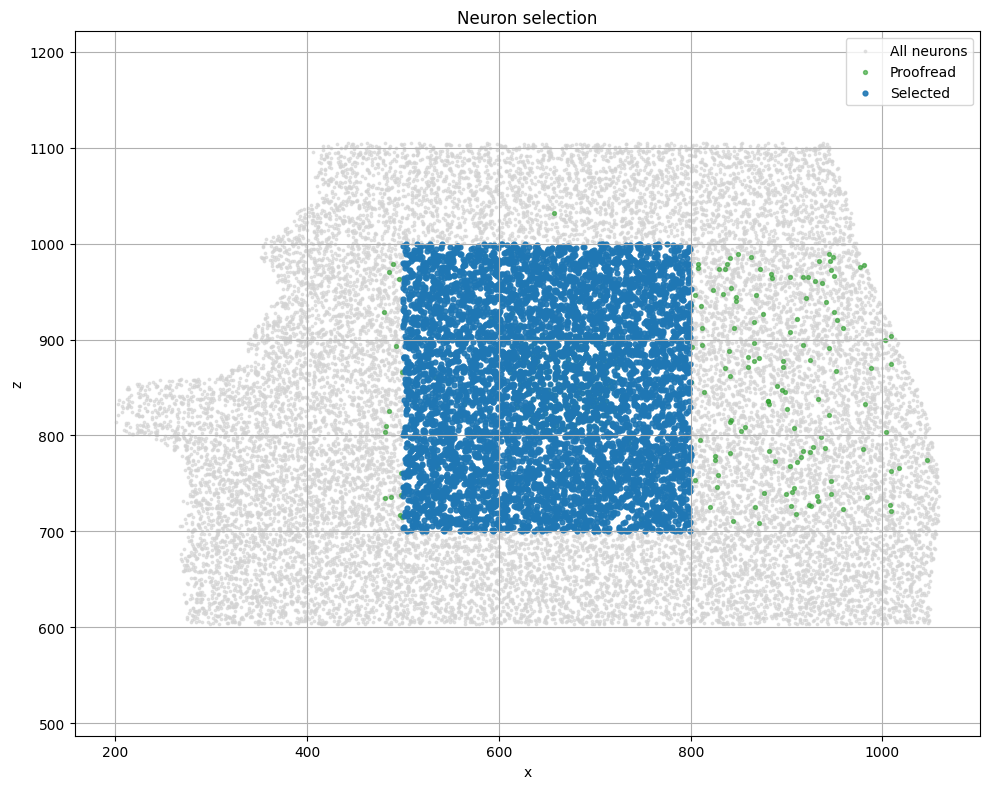

In [4]:
units_cleaned = clean_dataset(units)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

selected_mask = units_cleaned[(units_cleaned["pt_position_z"] < 1000) & (units_cleaned["pt_position_z"] > 700) & (units_cleaned["pt_position_x"] > 500) & (units_cleaned["pt_position_x"] < 800)]

print("selected_mask", selected_mask.shape)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [5]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (selected_mask['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (selected_mask['layer'] == 'L4')

In [6]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
print(E_L23.shape)
I_L23 = selected_mask[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = selected_mask[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = selected_mask[mask_inh & mask_l4].copy().reset_index(drop=True)

print(E_L23)

(3398, 11)
              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dend

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
AXON_CATEGORIES = [
    "none",
    "axon_partially_extended",
    "axon_fully_extended",
    "axon_interareal",
]

DENDRITE_CATEGORIES = [
    "none",
    "dendrite_extended",
    "dendrite_clean",
]

AXON_TO_INDEX = {
    name: index
    for index, name in enumerate(AXON_CATEGORIES)
}

DENDRITE_TO_INDEX = {
    name: index
    for index, name in enumerate(DENDRITE_CATEGORIES)
}

In [12]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [ ]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    id_to_pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]

    positions = id_to_pos.loc[
        np.array(all_ids)
    ].values.astype(np.float32)

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values

    positions = (positions - positions.mean(axis=0, keepdims=True)) / (positions.std(axis=0, keepdims=True)+ 1e-8)

    positions_um = id_to_pos.loc[
    np.asarray(all_ids)
    ].values.astype(np.float32)


    distance = df["euclidean"].to_numpy(
        dtype=np.float32
    )

    distance = (distance - distance.mean(axis=0, keepdims=True)) / (distance.std(axis=0, keepdims=True)+ 1e-8)




    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values

        # ========================================================
    # Proofreading information, ordered exactly like all_ids
    # ========================================================

    neuron_metadata = (
        units_cleaned
        .drop_duplicates("pt_root_id")
        .set_index("pt_root_id")
        .reindex(np.asarray(all_ids))
    )

    axon_labels = (
        neuron_metadata["strategy_axon"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    dendrite_labels = (
        neuron_metadata["strategy_dendrite"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    axon_indices = np.array([
        AXON_TO_INDEX.get(label, AXON_TO_INDEX["none"])
        for label in axon_labels
    ])

    dendrite_indices = np.array([
        DENDRITE_TO_INDEX.get(
            label,
            DENDRITE_TO_INDEX["none"]
        )
        for label in dendrite_labels
    ])

    axon_features = np.eye(
        len(AXON_CATEGORIES),
        dtype=np.float32
    )[axon_indices]

    dendrite_features = np.eye(
        len(DENDRITE_CATEGORIES),
        dtype=np.float32
    )[dendrite_indices]

    # Fully proofread definitions
    axon_fully_proofread = (
        axon_labels == "axon_fully_extended"
    ).astype(np.float32)

    dendrite_fully_proofread = (
        dendrite_labels == "dendrite_clean"
    ).astype(np.float32)

    
    features = [
    "pre_pt_position_x",
    "pre_pt_position_y",
    "pre_pt_position_z",
    "post_pt_position_x",
    "post_pt_position_y",
    "post_pt_position_z",
    ]

    print(df)

    X = df[features].to_numpy(dtype=np.float32)
    y = df['label'].values

    return (
    X,
    y,
    features,
    pre_idx,
    post_idx,
    positions,
    positions_um,
    distance,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
    )

In [ ]:
path, pre, post = pathways[0]
print(pre)
( _,
    y,
    _,
    pre_idx,
    post_idx,
    positions,
    positions_um,
    distance,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dendrite_extend

In [ ]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_latent_gesture_proofread_only_axon_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 100
PATIENCE = 10
LR = 1e-3
DIMS = [1,2,3,4,5,6,7,8,9,10]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class VisibilityAwareEmbeddingModel(nn.Module):

    def __init__(
        self,
        n_neurons,
        dim,
        positions,
        distance,
        axon_features,
        dendrite_features,
        axon_fully_proofread,
        dendrite_fully_proofread,
        hidden_connection=64,
        hidden_error=32,
    ):
        super().__init__()

        self.dim = dim

        # ====================================================
        # Latent embedding
        # ====================================================

        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # ====================================================
        # Fixed neuron information
        # ====================================================

        self.register_buffer(
            "positions",
            torch.as_tensor(
                positions,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_features",
            torch.as_tensor(
                axon_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "dendrite_features",
            torch.as_tensor(
                dendrite_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "distance",
            torch.as_tensor(
                distance,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_fully_proofread",
            torch.as_tensor(
                axon_fully_proofread,
                dtype=torch.bool
            )
        )

        self.register_buffer(
            "dendrite_fully_proofread",
            torch.as_tensor(
                dendrite_fully_proofread,
                dtype=torch.bool
            )
        )

        # ====================================================
        # P(connection)
        # Same branch as your previous hybrid model
        # ====================================================

        neuron_feature_dim = dim
        connection_input_dim = 2 * neuron_feature_dim

        self.connection_mlp = nn.Sequential(
            nn.Linear(
                connection_input_dim,
                hidden_connection
            ),
            nn.ReLU(),
            nn.Linear(hidden_connection, 1)
        )

        # ====================================================
        # P(error)
        #
        # Inputs:
        # - distance: 1
        # - pre axon category: 4
        # - post dendrite category: 3
        # ====================================================

        error_input_dim = (
            1
            + len(AXON_CATEGORIES)
        )

        self.error_mlp = nn.Sequential(
            nn.Linear(
                error_input_dim,
                hidden_error
            ),
            nn.ReLU(),
            nn.Linear(hidden_error, 1)
        )

        # Initially predict a relatively small error probability
        nn.init.constant_(
            self.error_mlp[-1].bias,
            -3.0
        )

    def forward_components(
        self,
        pre_idx,
        post_idx
    ):
        # ====================================================
        # Shared information
        # ====================================================

        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # ====================================================
        # 1. True connection probability
        # ====================================================

        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        h_pre = torch.cat(
            [z_pre],
            dim=1
        )

        h_post = torch.cat(
            [z_post],
            dim=1
        )

        connection_input = torch.cat(
            [h_pre, h_post],
            dim=1
        )

        connection_logits = (
            self.connection_mlp(
                connection_input
            )
            .squeeze(1)
        )

        p_connection = torch.sigmoid(
            connection_logits
        )

        # ====================================================
        # 2. Error probability
        # ====================================================

        axon_pre = self.axon_features[pre_idx]
        dendrite_post = (
            self.dendrite_features[post_idx]
        )

        distancenormalized = self.distance[torch.linalg.vector_norm(
            pos_pre - pos_post,
            dim=1
        ).unsqueeze(1)

        error_input = torch.cat(
            [
                distance,
                axon_pre
            ],
            dim=1
        )

        error_logits = (
            self.error_mlp(error_input)
            .squeeze(1)
        )


        p_error_raw = torch.sigmoid(
            error_logits
        )

        # ====================================================
        # Hard constraint:
        # fully proofread axon AND dendrite => P(error) = 0
        # ====================================================

        fully_proofread_pair = (
            self.axon_fully_proofread[pre_idx]
            & self.dendrite_fully_proofread[post_idx]
        )

        p_error = torch.where(
            fully_proofread_pair,
            torch.zeros_like(p_error_raw),
            p_error_raw
        )

        p_visible = 1.0 - p_error

        # ====================================================
        # Observed connection probability
        # ====================================================

        p_observed = (
            p_connection
            * p_visible
        )

        p_observed = torch.clamp(
            p_observed,
            min=1e-7,
            max=1.0 - 1e-7
        )

        return {
            "p_observed": p_observed,
            "p_connection": p_connection,
            "p_visible": p_visible,
            "p_error": p_error,
            "fully_proofread_pair": fully_proofread_pair,
        }

    def forward(
        self,
        pre_idx,
        post_idx
    ):
        return self.forward_components(
            pre_idx,
            post_idx
        )["p_observed"]

In [17]:
# =========================
# Data
# =========================

(
    _,
    y,
    _,
    pre_idx,
    post_idx,
    positions,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

100040
11543006
              pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0         864691134885142778  864691135446615698  0.321480         596.029358   
1         864691134885142778  864691135614255051  0.646090         596.029358   
2         864691134885142778  864691135726922303  3.349385         596.029358   
3         864691134885142778  864691135992246977  1.089187         596.029358   
4         864691134885735418  864691136522551953  0.549512         788.885071   
...                      ...                 ...       ...                ...   
11643041  864691136195316456  864691136032652987  0.000000         640.180115   
11643042  864691136195316456  864691136238038799  0.000000         640.180115   
11643043  864691136195316456  864691135778700477  0.000000         640.180115   
11643044  864691136195316456  864691135492080871  0.000000         640.180115   
11643045  864691136195316456  864691135865698780  0.000000         640.180115   

          p

In [18]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    all_y = []
    all_predictions = []

    with torch.no_grad():

        for pi, pj, yb in loader:

            p_observed = model(pi, pj)

            loss = criterion(
                p_observed,
                yb
            )

            total_loss += (
                loss.item() * len(yb)
            )

            all_y.append(
                yb.cpu().numpy()
            )

            all_predictions.append(
                p_observed.cpu().numpy()
            )

    all_y = np.concatenate(all_y)
    all_predictions = np.concatenate(
        all_predictions
    )

    auc = roc_auc_score(
        all_y,
        all_predictions
    )

    return (
        total_loss / len(loader.dataset),
        auc
    )

In [19]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [20]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [21]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [22]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=dim,
    positions=positions,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
    ).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCELoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            p_observed = model(pi, pj)
            loss = criterion(p_observed, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
Resuming dim=1 from checkpoints_embedding_MLP_latentV2_gesture_proofread_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\last_dim_1.pt
Resumed at epoch 39 | best_epoch=28 | best_val_auc=0.8739
dim=01 | epoch=039 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8738
dim=01 | epoch=040 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8740
dim=01 | epoch=041 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8737
dim=01 | epoch=042 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8739
dim=01 | epoch=043 | train_loss=0.0396 | val_loss=0.0398 | val_auc=0.8740
dim=01 | epoch=044 | train_loss=0.0396 | val_loss=0.0398 | val_auc=0.8741
dim=01 | epoch=045 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8739
dim=01 | epoch=046 | train_loss=0.0396 | val_loss=0.0398 | val_auc=0.8739
dim=01 | epoch=047 | train_loss=0.0396 | val_loss=0.0399 | val_auc=0.8738
dim=01 | epoch=048 | train_loss=0.0396 | val_loss=0.0398 | val_auc=0.8740
dim=01 | ep

KeyboardInterrupt: 

In [ ]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS

coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



In [ ]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1
ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
    ).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

# ============================================================
# Remove duplicates
# ============================================================

units_unique = (
    units_cleaned
    .drop_duplicates(
        subset="pt_root_id",
        keep="first"
    )
    .copy()
)

print(
    "Duplicates in units_unique:",
    units_unique["pt_root_id"].duplicated().sum()
)


# ============================================================
# Build df_Z_full
# ============================================================

df_Z_full = df_Z.merge(
    units_unique,
    on="pt_root_id",
    how="left"
)
print(df_Z_full.head())

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np


# ============================================================
# Data
# ============================================================

df_Z_full = df_Z_full.merge(readout_unique[ 
    ["pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(df_Z_full)


df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

R = np.stack(df_Z_readout["readout_weight"].values)

print("R shape:", R.shape)

threshold = 0.30

results = []

# ============================================================
# Correlations
# ============================================================

for z in latent_cols:

    z_values = df_Z_readout[z].values

    for j in range(512):

        rho, pval = spearmanr(
            z_values,
            R[:, j]
        )

        if np.abs(rho) >= threshold:

            results.append({
                "latent": z,
                "readout_dim": j,
                "rho": rho,
                "abs_rho": abs(rho),
                "pvalue": pval,
            })

corr_df = pd.DataFrame(results)

"""corr_df = corr_df.sort_values(
    "abs_rho",
    ascending=False
)"""

print(corr_df)

In [ ]:
# ============================================================
# Empirical P(connection) as a function of Z_pre and Z_post
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


N_BINS = 20
MIN_PAIRS_PER_CELL = 100


# Existing tensors -> NumPy
pre_np = pre_idx.detach().cpu().numpy()
post_np = post_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()


heatmaps = []
edges_by_dim = []


# ============================================================
# Compute empirical probabilities
# ============================================================

for k in range(DIM_TO_ANALYZE):

    z_pre = Z[pre_np, k]
    z_post = Z[post_np, k]

    z_edges = np.linspace(
        min(z_pre.min(), z_post.min()),
        max(z_pre.max(), z_post.max()),
        N_BINS + 1,
    )

    # Number of possible connections in each cell
    n_possible, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
    )

    # Number of observed connections in each cell
    n_connections, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
        weights=y_np,
    )

    # P(connection) = observed / possible
    empirical_probability = np.divide(
        n_connections,
        n_possible,
        out=np.full_like(
            n_connections,
            np.nan,
            dtype=float,
        ),
        where=n_possible > 0,
    )

    empirical_probability[
        n_possible < MIN_PAIRS_PER_CELL
    ] = np.nan

    heatmaps.append(empirical_probability)
    edges_by_dim.append(z_edges)


# Common color scale
vmax = np.nanmax([
    np.nanmax(heatmap)
    for heatmap in heatmaps
])


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    DIM_TO_ANALYZE,
    figsize=(5 * DIM_TO_ANALYZE, 4.5),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")


for k, ax in enumerate(axes):

    z_edges = edges_by_dim[k]

    im = ax.pcolormesh(
        z_edges,
        z_edges,
        heatmaps[k].T,
        shading="auto",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(
        rf"Latent dimension $Z_{k+1}$"
    )

    ax.set_xlabel(
        rf"Presynaptic value $Z_{{i,{k+1}}}$"
    )

    ax.set_ylabel(
        rf"Postsynaptic value $Z_{{j,{k+1}}}$"
    )


colorbar = fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.85,
)

colorbar.set_label(
    "Empirical connection probability"
)

colorbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

fig.suptitle(
    "Empirical connection probability in latent space",
    fontsize=14,
)

plt.savefig(
    "empirical_connection_probability_latent_heatmaps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
    "readout_mu_x",
    "readout_mu_y"
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

In [ ]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

In [ ]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

In [ ]:
import pickle
import h5py
import pandas as pd

with open("MICrONS\\readout_info\\foundation_model.pkl", "rb") as f:
    foundation = pickle.load(f)

with open("MICrONS\\readout_info\\hierarchical_model.pkl", "rb") as f:
    hierarchical = pickle.load(f)

h5 = h5py.File("MICrONS\\microns.h5", "r")
print(h5.keys())

In [ ]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

feature = "readout_weight"

# neurones valides
df = df_Z_full.dropna(subset=[feature]).copy()

idx = df["neuron_idx"].values

Z_valid = Z[idx]

# IMPORTANT : convertir la colonne de vecteurs en matrice
F = np.stack(
    df[feature].values
).astype(np.float32)

print("Z_valid shape:", Z_valid.shape)
print("F shape:", F.shape)

# -------------------------
# échantillonnage
# -------------------------

n_pairs = 200000
rng = np.random.default_rng(42)

i = rng.integers(0, len(df), n_pairs)
j = rng.integers(0, len(df), n_pairs)

mask = i != j
i = i[mask]
j = j[mask]

# -------------------------
# distances
# -------------------------

latent_dist = np.linalg.norm(
    Z_valid[i] - Z_valid[j],
    axis=1
)

feature_dist = np.linalg.norm(
    F[i] - F[j],
    axis=1
)

rho, pval = spearmanr(
    feature_dist,
    latent_dist
)

print(f"Spearman rho = {rho:.3f}, p = {pval:.2e}")

# -------------------------
# dataframe
# -------------------------

res = pd.DataFrame({
    "feature_dist": feature_dist,
    "latent_dist": latent_dist
})

res["bin"] = pd.cut(
    res["feature_dist"],
    bins=30
)

curve = res.groupby("bin").agg(
    mean_latent=("latent_dist", "mean"),
    n_pairs=("latent_dist", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# -------------------------
# plot
# -------------------------

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["mean_latent"],
    marker="o"
)

plt.xlabel("||Vi - Vj||")
plt.ylabel("Mean ||Zi - Zj||")
plt.title(
    f"Latent distance vs readout-vector distance\nSpearman rho = {rho:.3f}"
)

plt.grid(True)
plt.tight_layout()
plt.show()